# 06 — A* Path Planning

A* per robot domain (Section 18): UGV on LAND cells, USV on WATER cells,
UAV over AIR/LAND/WATER, respecting obstacles, FORBIDDEN zones, and using
RESTRICTED-zone/risk as an edge-cost surcharge. The path length/cost is
NOT used only for visualization — it directly feeds the auction bid
(notebook 07).

In [1]:
import sys, os
sys.path.append(os.path.abspath("C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/src"))
import matplotlib.pyplot as plt

from environment import Environment
from robots import RobotFleet
from tasks import TaskManager
from astar import astar
from visualization import plot_environment

DATASET_ROOT = "C:/Users/bomma/Desktop/DESKTOP_MAIN_DISP/MATHS_PROJECT_SEM5/A_project_re/project_COMPLETE_all_5_days/project/data/dataset"
env = Environment(DATASET_ROOT)
fleet = RobotFleet(DATASET_ROOT)
tm = TaskManager(DATASET_ROOT)


## Plan a path per robot type and visualize it

UGV02 (UGV) -> T04: found=True, path_length=41.7, travel_cost=54.2, est_time=22.6
USV01 (USV) -> T13: found=True, path_length=15.7, travel_cost=25.1, est_time=4.1
UAV02 (UAV) -> T03: found=True, path_length=14.8, travel_cost=19.3, est_time=2.4


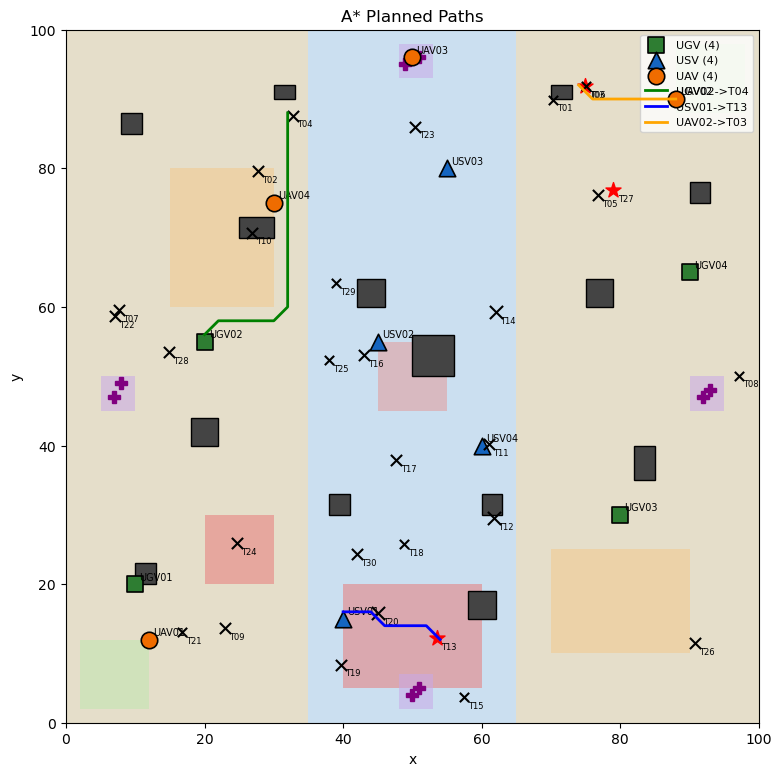

In [2]:
examples = [
    ("UGV02", "T04"),  # UGV -> LAND task
    ("USV01", "T13"),  # USV -> WATER task (emergency)
    ("UAV02", "T03"),  # UAV -> INSPECTION emergency task
]

fig, ax = plot_environment(env, fleet, tm, title="A* Planned Paths")
results = {}
colors = {"UGV02": "green", "USV01": "blue", "UAV02": "orange"}

for robot_id, task_id in examples:
    robot = fleet.robots[robot_id]
    task = tm.tasks[task_id]
    result = astar(env, (robot.x, robot.y), (task.x, task.y), robot.robot_type, step=2)
    results[(robot_id, task_id)] = result
    print(f"{robot_id} ({robot.robot_type}) -> {task_id}: found={result.found}, "
          f"path_length={result.path_length:.1f}, travel_cost={result.travel_cost:.1f}, "
          f"est_time={result.estimated_time(robot.speed):.1f}")
    if result.found:
        xs = [p[0] for p in result.path]
        ys = [p[1] for p in result.path]
        ax.plot(xs, ys, "-", linewidth=2, color=colors[robot_id], zorder=9, label=f"{robot_id}->{task_id}")

ax.legend(loc="upper right", fontsize=8)
fig.savefig("../results/day2_astar_paths.png", dpi=150, bbox_inches="tight")


## Sanity check: domain constraints are respected

In [3]:
# A UGV should NOT be able to path through a WATER-only goal cell
r = astar(env, (20, 55), (50, 10), "UGV", step=2)
assert not r.found, "UGV should not reach a water-only cell"
print("OK: UGV correctly blocked from a water-only destination.")

for (robot_id, task_id), result in results.items():
    assert result.found, f"{robot_id}->{task_id} should have found a path"
print("OK: all example robot-task paths were found successfully.")


OK: UGV correctly blocked from a water-only destination.
OK: all example robot-task paths were found successfully.


# iproved figure

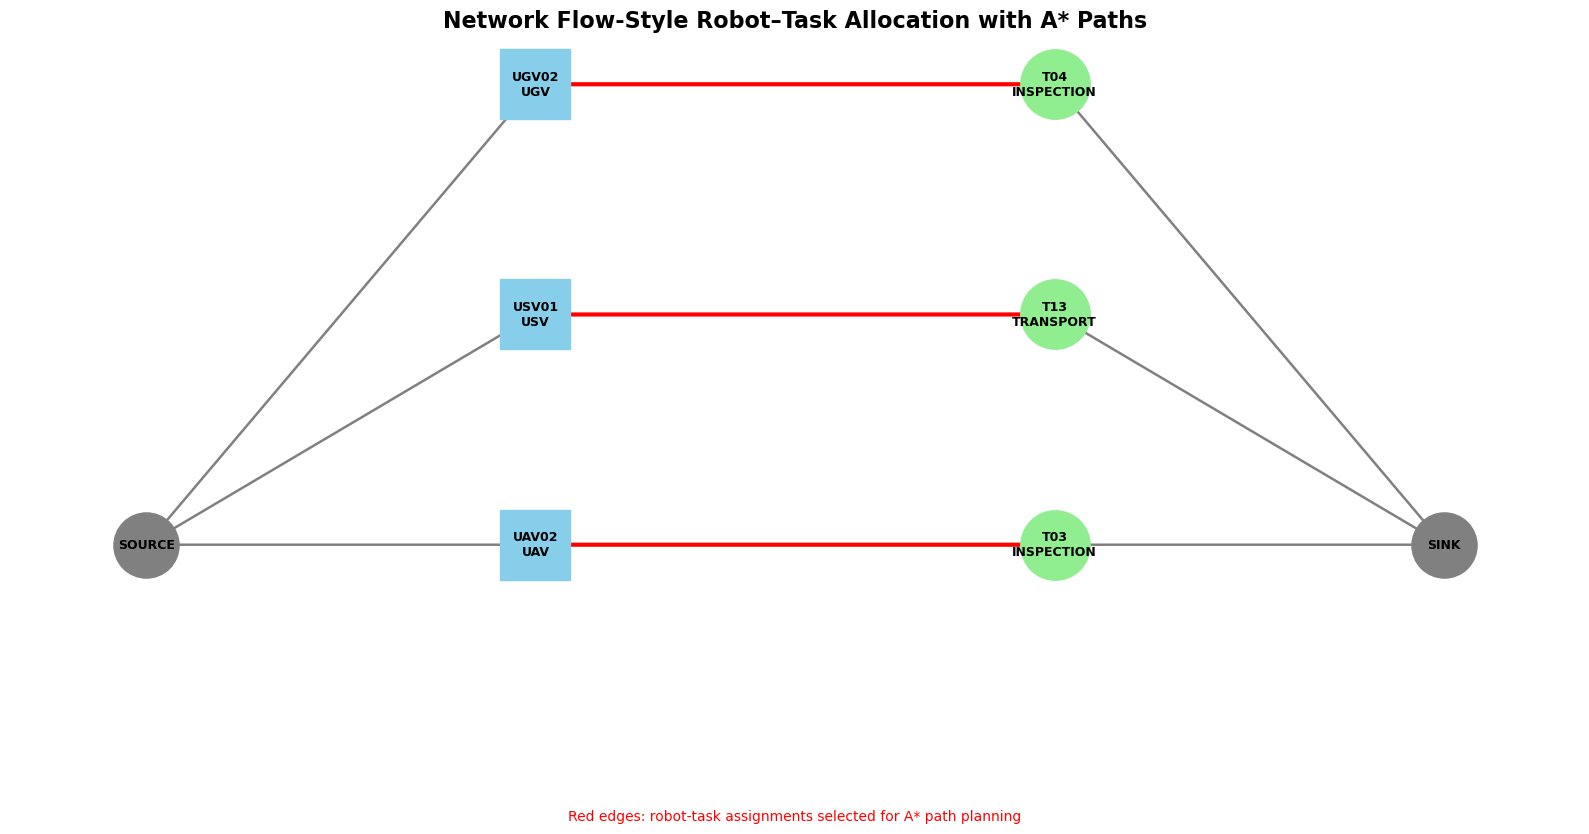

In [5]:
# Network Flow-style visualization with A* paths

import matplotlib.pyplot as plt
import networkx as nx

flow_graph = nx.DiGraph()

SOURCE = "SOURCE"
SINK = "SINK"

flow_graph.add_node(SOURCE, kind="source")
flow_graph.add_node(SINK, kind="sink")

robot_nodes = []
task_nodes = []

# Create layered nodes
for robot_id, task_id in examples:
    robot = fleet.robots[robot_id]
    task = tm.tasks[task_id]

    robot_node = f"R:{robot_id}"
    task_node = f"T:{task_id}"

    flow_graph.add_node(
        robot_node,
        kind="robot",
        label=f"{robot_id}\n{robot.robot_type}"
    )

    flow_graph.add_node(
        task_node,
        kind="task",
        label=f"{task_id}\n{getattr(task, 'task_type', 'Task')}"
    )

    flow_graph.add_edge(SOURCE, robot_node)
    flow_graph.add_edge(robot_node, task_node)
    flow_graph.add_edge(task_node, SINK)

    robot_nodes.append(robot_node)
    task_nodes.append(task_node)

# Layered positions
pos = {
    SOURCE: (0, 0),
    SINK: (10, 0)
}

for i, node in enumerate(robot_nodes):
    pos[node] = (3, len(robot_nodes) - i - 1)

for i, node in enumerate(task_nodes):
    pos[node] = (7, len(task_nodes) - i - 1)

plt.figure(figsize=(16, 9))

# Draw source and sink
nx.draw_networkx_nodes(
    flow_graph,
    pos,
    nodelist=[SOURCE, SINK],
    node_color="gray",
    node_shape="o",
    node_size=2200
)

# Draw robots
nx.draw_networkx_nodes(
    flow_graph,
    pos,
    nodelist=robot_nodes,
    node_color="skyblue",
    node_shape="s",
    node_size=2500
)

# Draw tasks
nx.draw_networkx_nodes(
    flow_graph,
    pos,
    nodelist=task_nodes,
    node_color="lightgreen",
    node_shape="o",
    node_size=2500
)

# Draw normal flow connections
nx.draw_networkx_edges(
    flow_graph,
    pos,
    edgelist=[
        edge for edge in flow_graph.edges()
        if edge[0] == SOURCE or edge[1] == SINK
    ],
    edge_color="gray",
    width=1.8,
    arrows=True,
    arrowsize=18
)

# Draw robot-task assignment edges
nx.draw_networkx_edges(
    flow_graph,
    pos,
    edgelist=[
        (f"R:{robot_id}", f"T:{task_id}")
        for robot_id, task_id in examples
    ],
    edge_color="red",
    width=3,
    arrows=True,
    arrowsize=20
)

# Labels
labels = {
    SOURCE: "SOURCE",
    SINK: "SINK"
}

for node, data in flow_graph.nodes(data=True):
    if node not in [SOURCE, SINK]:
        labels[node] = data["label"]

nx.draw_networkx_labels(
    flow_graph,
    pos,
    labels=labels,
    font_size=9,
    font_weight="bold"
)

plt.title(
    "Network Flow-Style Robot–Task Allocation with A* Paths",
    fontsize=16,
    fontweight="bold"
)

plt.text(
    5,
    -1.2,
    "Red edges: robot-task assignments selected for A* path planning",
    ha="center",
    fontsize=10,
    color="red"
)

plt.axis("off")
plt.tight_layout()
plt.show()